# 05b — Energy landscape and descent animation

**Background resource:** Section numbers below refer to the [August perspective](../../paper/background/august-perspective.pdf), preserved alongside the current paper.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models-publication/blob/main/code/notebooks/05b_multistable_animation.ipynb)

Companion to §6 of *From Brains to Models*. Notebook 05 is the controlled demonstration (Hopfield descent, Necker switching, attention as one retrieval step). This notebook is the *map*: a multi-well surface $U(\mathbf{X})$ over two activity coordinates, a gradient path into a valley, an animation of that descent, and an interactive picker: drop a start and watch which attractor wins.

The surface is the same family as the [KI-i-helsefagene illustration](https://github.com/arvidl/KI-i-helsefagene/blob/main/Optimering/notebooks/illustrasjon-av-optimering-og-multistabile-dynamiske-systemer.ipynb), after the schematic in Kandel et al., *Principles of Neural Science* (5th ed., Fig. E-7). It is a designed teaching function. It is not a measured cortical energy, not $5\cdot 10^9$ neurons, and not the Hopfield $E$ of notebook 05.

**Claim.** Cognition can be drawn as trajectories on a multistable energy; the start determines which attractor wins.

**Method.** Designed teaching surface $U(\mathbf{X})$ over two coordinates; gradient descent; optional animation. Seed 7.

**Result.** The landscape figure and a descent path into a local minimum.

**Limit.** Not a measured cortical energy, not $5\cdot 10^9$ neurons, not the Hopfield $E$ of notebook 05.

<details>
<summary><b>Key terms — for clinicians and neuroscientists</b></summary>

- **Energy (potential) landscape.** A surface whose height is "energy" over two activity coordinates; the system rolls downhill. Valleys are stable states and ridges separate them — a common way to picture a multistable dynamical system.
- **[Attractor](https://en.wikipedia.org/wiki/Attractor) and basin.** A valley the dynamics settle into (attractor) and the region of starts that lead there (its basin). Which valley wins depends on where you begin.
- **Gradient descent.** Moving in the direction of steepest downhill slope — here the rule that traces the path from a start into a valley.
- **Multistability and initial conditions.** Several valleys coexist; a small change in the starting point can send the path to a different one. The interactive picker makes this visible.
- **Designed teaching surface.** The landscape is drawn to illustrate, not measured from a brain — a schematic in the tradition of the energy diagrams in *Principles of Neural Science*.

</details>

<details>
<summary><b>Key terms — for the mathematically inclined</b></summary>

- **Surface.** A designed potential $U(\mathbf{X})$ over two coordinates $\mathbf{X}=(x_1,x_2)$ with several local minima.
- **Descent.** $\mathbf{X}_{k+1}=\mathbf{X}_k-\eta\,\nabla U(\mathbf{X}_k)$ traces a path to a local minimum.
- **Basins.** The partition of the plane by which minimum descent reaches; the boundaries are ridges/saddles of $U$.
- **Sensitivity.** Near a ridge, close starts (for example $(-2.50,-3.50)$ versus $(-2.18,-3.50)$) diverge to different wells.
- **Distinct energies.** $U$ is a teaching function — not variational [free energy](https://en.wikipedia.org/wiki/Free_energy_principle) and not the Hopfield $E$ of notebook 05.

</details>

Writes `paper/figures/energy_landscape.pdf` (`make figures`) and the descent animation `code/animations/energy_landscape.gif` plus `.mp4` when `ffmpeg` is available on `PATH`.

Reproducible: `SEED = 7` in the setup cell. Restart and run all to reproduce the figure.

### Concepts used in this notebook

This notebook draws a multi-well energy surface, traces gradient descent into a valley, animates the descent, and lets you drop a start to see which attractor wins. The two blocks below define the recurring terms once, first in plain language and then in notation. Both cover the same concepts at a different level of detail.

<details>
<summary><b>Concepts — for clinicians and neuroscientists</b></summary>

- **Landscape metaphor for cognition.** States of a neural system pictured as positions on a surface — thinking as movement, a decision as settling into a valley.
- **Local versus global minimum.** The deepest valley is the global minimum; descent can stop in a shallower local one, depending on the start.
- **Ridge / saddle.** The high ground between valleys; crossing it takes a push — a different start, or noise.
- **Attractor competition.** Two nearby starts on opposite sides of a ridge end in different valleys — the point the picker demonstrates.
- **Animation versus claim.** The moving dot is a teaching aid for descent, not a recording of neural activity.
- **What this is and is not.** A designed surface for intuition — not a measured cortical energy, not billions of neurons, and not the Hopfield energy of notebook 05.

</details>

<details>
<summary><b>Concepts — for the mathematically inclined</b></summary>

- **Potential.** A designed $U(\mathbf{X})$, $\mathbf{X}\in\mathbb{R}^2$, with several minima.
- **Dynamics.** Gradient descent $\mathbf{X}_{k+1}=\mathbf{X}_k-\eta\,\nabla U(\mathbf{X}_k)$, with an optional animation of the trajectory.
- **Basins.** Which minimum is reached as a function of the start; ridges act as separatrices.
- **Sensitivity.** A documented start pair straddling a ridge.
- **Setup.** Seed 7.
- **Limit.** Three energies must stay distinct — the teaching $U$, the Hopfield $E$, and the training loss; none is [free energy](https://en.wikipedia.org/wiki/Free_energy_principle) and none is felt.

</details>

In [1]:
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np

REPO = os.environ.get("BRAINSMODELS_REPO_URL",
                      "https://github.com/arvidl/brains-to-models-publication.git")
COLAB_ROOT = Path("/content/brains-to-models")

if "google.colab" in sys.modules:
    if not (COLAB_ROOT / "code" / "src" / "brainsmodels").is_dir():
        subprocess.check_call(["git", "clone", "--depth", "1", REPO, str(COLAB_ROOT)])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ipympl"])
    root = COLAB_ROOT
else:
    here = Path.cwd().resolve()
    root = here.parents[1] if here.name == "notebooks" else here

src = root / "code" / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.landscape import (
    DEFAULT_START,
    descend,
    energy,
    explore_descent,
    render_paper_figure,
    write_animation,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)

repo root: <checkout>
seed: 7


## A designed surface, not a measured brain

Two coordinates $(x,y)$ stand in for a slice of activity space. The energy is a handful of sines plus a weak quadratic bowl — enough wells to look like a landscape, few enough to read:

$$
U(x,y)=(\sin x+\sin\tfrac12 x)\cos y+(\cos\tfrac32 x+\cos\tfrac34 x)\sin\tfrac12 y+0.1(x^2+y^2).
$$

Gradient descent $ \mathbf{X}\leftarrow\mathbf{X}-\eta\nabla U $ is the yellow path. The well it reaches is an attractor: a memory, a percept, a decision — *in the schematic*. The ambient space of a cortex is not $\mathbb{R}^2$. The function is not fit to data.

In [2]:
path = descend(start=DEFAULT_START)
z = energy(path[:, 0], path[:, 1])
print(f"start {path[0]}  U={float(z[0]):+.3f}")
print(f"end   {path[-1]}  U={float(z[-1]):+.3f}")
print(f"steps {len(path)}  ΔU={float(z[-1] - z[0]):+.3f}")

start [0.8 4.8]  U=+3.267
end   [2.119 2.85 ]  U=-1.398
steps 59  ΔU=-4.666


## Paper figure

The static view for §6. Caption and title state exactly what it is: a 2-D slice, a designed $U$, one descent.

In [3]:
fig = render_paper_figure(path)
plt.show()
write_figure(root / "paper" / "figures", path=path)

/var/folders/1g/_4x26lps6mgg1tr73d7g2bmh0000gp/T/ipykernel_49892/1965254379.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


wrote <checkout>/paper/figures/energy_landscape.pdf
wrote <checkout>/paper/figures/energy_landscape.png


PosixPath('<checkout>/paper/figures/energy_landscape.pdf')

## Descent animation

The same path, drawn a step at a time. GIF always; MP4 if `ffmpeg` is on the `PATH`. Colab will write into the cloned repo under `/content`.

In [4]:
gif = write_animation(root / "code" / "animations")
print("animation:", gif)

wrote <checkout>/code/animations/energy_landscape.gif


wrote <checkout>/code/animations/energy_landscape.mp4  (/opt/homebrew/bin/ffmpeg)
animation: <checkout>/code/animations/energy_landscape.gif


## Drop a start, watch a basin win

The paper figure and the animation use one start. Multistability is the fact that **a different start can drain into a different well**. Click the contour map (or drag the sliders) to drop a point on $U$. Gradient descent then runs to the nearest attractor.

Needs `ipywidgets` and `ipympl` (both in this repo’s `.venv`; the setup cell installs `ipympl` on Colab). If click or rotation is unavailable, use the sliders — they run the same descent.

HTML(value='<i>Click the contour to drop a start (green). The path ends at a red attractor. Drag the 3-D panel…

HTML(value='')

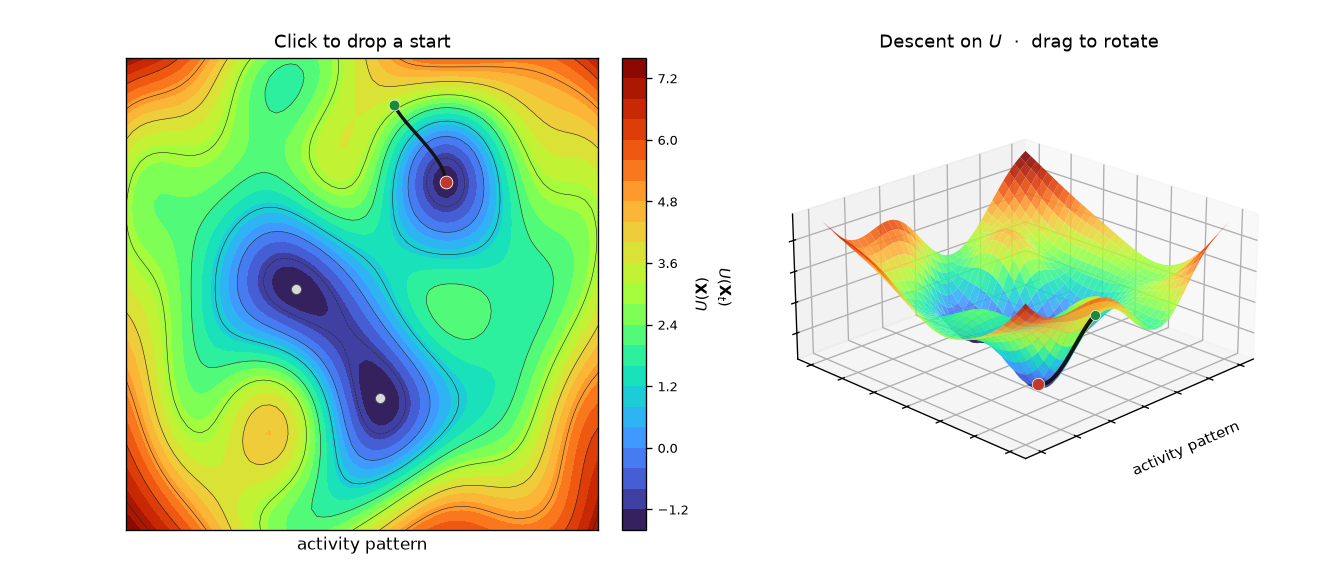

In [5]:
%matplotlib widget
explore_descent()

## What to notice

**This is a map, not a measurement.** The wells are where we put them. A cortex, a Hopfield net, and a transformer each have a *different* $U$ (or none that is this $U$). The shared fact is the *shape*: more than one valley, descent as a computation, the bottom as a content.

**Notebook 05 is why the shape is not enough.** There, $E$ is a Lyapunov function on a hypercube and cannot rise. Here $U$ is a convenience for the eye. Confusing the two is how “the brain minimises energy” becomes a slogan.

**The animation does not add a theorem.** It adds time. A static arrow says “down.” A gif says “this starting point, this well.” The picker above is the same fact by hand: drop two starts and you can land in two wells. That is a basin boundary, not an artifact.

**No brain photograph.** The Kandel schematic had one. We do not reproduce it. The claim does not need a stock MRI.

## Why this example is here

This notebook is the map for §6, not a model of cortex and not a second Hopfield net. It exists so that the sentence *cognition unfolds as trajectories on a multistable landscape* is something you can point at before notebook 05 puts a Lyapunov function and a Necker well on the table.

The intended readers are the same as the paper’s. The two readings below are of the *same* surface.

**For the clinician and the neuroscientist.** You already use this picture. A memory that “comes back,” a percept that settles, a decision that clicks — each is a system that stopped moving in a familiar place. The yellow path is a history becoming that place. A different start (a different cue, a different framing) can drain into a different well: that is misrecognition, a Necker flip, a changed plan. The slide in Kandel is this intuition for a generation of students. The paper keeps the intuition and then, in notebook 05, refuses to let it float free of a state space. Nothing here is a patient, an fMRI, or $5\cdot 10^9$ firing neurons. Those numbers on the original slide are a slogan about ambient dimension, not a count we performed.

**For the mathematically inclined.** $U:\mathbb{R}^2\to\mathbb{R}$ is $C^\infty$. The path is explicit Euler on $-\nabla U$ with a fixed $\eta$. It is not a stochastic gradient, not Langevin (that is notebook 05 panel C), and not a discrete Hopfield map. Local minima of this $U$ are not the Hebb-stored $\xi_\mu$. The 3-D plot is a graph of a scalar, not a 2-D projection of a high-dimensional $E$. The only structure that transfers to the rest of §6 is: $\mathrm{crit}(U)$ has more than one sink, and the basin of a sink is a set of initial conditions.

Change the start point. The surface stays. The claim should too: **a designed multi-well $U$, one descent, an attractor as a content — then go to notebook 05 for a $U$ that is actually an energy.**

### Questions for reflection

Not a quiz. Each question can be asked of a brain and of a machine. Write a short answer that a clinician or a neuroscientist, and a mathematically inclined reader, could both test. The two themes are defined in Further reading below.


1. Nearby starts fall into two different wells. What does that say about a slight change of history, or of prompt?

2. The surface is a teaching function, not the Hopfield $E$ of notebook 05 and not a measured cortical energy. What comparison is still licensed?

3. Step size: too large and you jump wells; too small and you crawl. What clinical “update size” is that a schematic of?

4. Energy along a gradient path should not rise. If it rose, what would you have changed — the designed $U$, or the integrator?

5. “The start determines which attractor wins.” Write that as a statement true of a brain description and of a model description.

6. A body that must stay in a viable region is not a ball on a designed $U(\mathbf{X})$. What constraint is missing from the surface? ([Allostasis](https://en.wikipedia.org/wiki/Allostasis).)

7. In the interactive picker you choose the start. Who chooses the start in a person, and who chooses it in a sampled completion?

8. The animation is the same descent, drawn. What does watching it add that the static figure does not, and what does it still not measure?

9. Three attractors on a square. Why is counting wells not a theory of thought?

10. If two systems share a landscape sketch, have they agreed at implementation?


### Further reading

Each annotation is written against the two themes: **(i) From brains to models** asks what a comparison can establish at a computational level: the same objective, the same representation, the same dynamical description, or the same functional test, applied on both sides — brain and model (machine). **(ii) What AI reveals about being human** asks what the comparison isolates when the systems (human and machine) diverge: [embodiment](https://plato.stanford.edu/entries/embodied-cognition/), a body that must satisfy [allostasis](https://en.wikipedia.org/wiki/Allostasis) (viability) constraints, [phenomenal experience](https://plato.stanford.edu/entries/consciousness/), and values that originate in need and [homeostasis](https://en.wikipedia.org/wiki/Homeostasis) rather than in training data.

The demonstrations in this notebook are teaching models. They illustrate a principle at a scale that can be run and modified. They are not recordings from cortex, not evaluations of a large language model, and not evidence that a next-token probability is a value.

Bibliographic links open the paper or a stable copy. Linked terms open a short definition.

1. **Hopfield, J. J. (1982).** [*Neural networks and physical systems with emergent collective computational abilities*](https://redwood.berkeley.edu/wp-content/uploads/2018/08/hopfield82.pdf). *PNAS* 79(8), 2554–2558. Opened PDF.
   - *(i) From brains to models.* The physical meaning of content-addressable memory is “an appropriate phase space flow of the state of a system.” This notebook is that sentence as a surface $U(\mathbf{X})$: drop a start, watch which [attractor](https://en.wikipedia.org/wiki/Attractor) wins.
   - *(ii) What AI reveals about being human.* A teaching slice is not $5\cdot 10^9$ neurons and not a measured cortical energy. The path is designed. The claim that survives is the language: start, well, ridge.

2. **Ramsauer, H., et al. (2020).** [*Hopfield Networks is All You Need*](https://arxiv.org/abs/2008.02217). arXiv:2008.02217.
   - *(i) From brains to models.* Why notebook 05’s attention panel belongs on the same map: one softmax retrieval in a landscape of keys. The animation here is gradient descent on a *designed* $U$, not that softmax, and not the training loss.
   - *(ii) What AI reveals about being human.* Three energies travel together and must stay distinct: the teaching $U$, the Hopfield $E$, and the training loss. None of them is a felt state.

3. **Necker, L. A. (1832).** [*Observations on some remarkable optical phaenomena…*](https://en.wikipedia.org/wiki/Necker_cube). Entry via the opened Necker-cube page.
   - *(i) From brains to models.* Nearby starts on this surface are the dynamical cousin of two interpretations of the [cube](https://en.wikipedia.org/wiki/Necker_cube): a ridge, two wells, a start that decides. The exercise with $(-2.50,-3.50)$ vs $(-2.18,-3.50)$ is that fact as coordinates.
   - *(ii) What AI reveals about being human.* Choosing a start with a click is not perceiving a cube. The remainder is the switch you cannot help seeing, which no yellow path reports.

4. **Friston, K. (2010).** [*The free-energy principle: a unified brain theory?*](https://www.fil.ion.ucl.ac.uk/~karl/The%20free-energy%20principle%20A%20unified%20brain%20theory.pdf). *Nature Reviews Neuroscience* 11, 127–138. Author PDF.
   - *(i) From brains to models.* Descent on a free-energy landscape is the other famous energy story. This $U$ is *not* variational free energy. Do not read the teal minimum as [FEP](https://en.wikipedia.org/wiki/Free_energy_principle) inference. It is a teaching well.
   - *(ii) What AI reveals about being human.* FEP energy is a bound on surprisal for an agent that persists. A designed surface has no [viability](https://en.wikipedia.org/wiki/Allostasis) constraint. Keep the names apart.

5. **Doerig, A., et al. (2023).** [*The neuroconnectionist research programme*](https://konklab.fas.harvard.edu/Papers/Doerig_2023_NRN.pdf). *Nature Reviews Neuroscience* 24, 431–450.
   - *(i) From brains to models.* A drawable landscape is a computational hypothesis: cognition as trajectories on a multistable energy. The programme asks whether that hypothesis earns its keep by generating comparisons that can fail (different starts, different wells).
   - *(ii) What AI reveals about being human.* A hypothesis you can click is still a schematic. Theme (ii) is the lived trajectory — a life that does not reset when you pick a new start.


### Exercises

1. **Nearby starts, two wells.** The teaching surface $U(x,y)$ has several listed attractors. Descend from `(-2.50, -3.50)` and from `(-2.18, -3.50)` — 0.32 apart. Which well does each path enter? What does a ridge between nearby starts say about a prompt that sits near a saddle?

<!-- solution-box: 05b_1_nearby_starts_two_wells.py -->
<details>
<summary><strong>Show solution</strong> — Nearby starts, two wells</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05b_1_nearby_starts_two_wells.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.landscape import ATTRACTORS, descend, energy, nearest_attractor
starts = ((-2.50, -3.50), (-2.18, -3.50), (0.80, 4.80))
print(f"{'start':<16}{'end':<16}{'U(end)':>8}  well")
for s in starts:
    path = descend(s)
    end = tuple(float(v) for v in path[-1])
    well = nearest_attractor(end, radius=0.6)
    print(f"{s!s:<16}{end!s:<16}{float(energy(*end)):>8.3f}  {well}")

print(
    "\nA small shift in the start can change the basin. On this surface "
    "that is a ridge in U. In the paper's reading, a slight rewording "
    "of a prompt is a perturbation near a saddle — a teaching analogy, "
    "not a measurement of a frontier model, and not a Hopfield net "
    "(that is notebook 05)."
)
```

</details>
<!-- /solution-box -->


2. **Step size.** `descend` takes `lr`. From the default start, compare `lr=0.02` and `lr=0.25`: path length, final energy, and whether `nearest_attractor` still returns a listed well. When does a large step leave the teaching picture?

<!-- solution-box: 05b_2_step_size.py -->
<details>
<summary><strong>Show solution</strong> — Step size</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05b_2_step_size.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.landscape import DEFAULT_START, descend, energy, nearest_attractor
for lr in (0.02, 0.08, 0.25):
    path = descend(DEFAULT_START, lr=lr, n_steps=200)
    end = path[-1]
    well = nearest_attractor(tuple(end), radius=0.6)
    print(
        f"lr {lr:.2f}  steps {len(path):3d}  U={float(energy(*end)):+.3f}  "
        f"well {well}"
    )
print(
    "\nA small step crawls; the default step is the figure; a large step "
    "can overshoot a well or leave the plotted square (the path is "
    "clipped). The surface is a teaching slice of activity space, not "
    "SGD on a transformer loss. Notebook 05 is the controlled "
    "demonstration; this one is the map."
)
```

</details>
<!-- /solution-box -->


3. **Energy along the path.** Plot $U$ along the default descent. Is the sequence monotone? If a step rises, what in `descend` allowed it — and what would a true gradient flow have done?

<!-- solution-box: 05b_3_energy_along_the_path.py -->
<details>
<summary><strong>Show solution</strong> — Energy along the path</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05b_3_energy_along_the_path.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.landscape import DEFAULT_START, descend, energy
path = descend(DEFAULT_START)
u = np.array([float(energy(x, y)) for x, y in path])
ups = int(np.sum(np.diff(u) > 1e-9))
print(f"steps {len(path)}  ΔU {u[-1] - u[0]:+.3f}  uphill steps {ups}")

fig, ax = plt.subplots(figsize=(5.2, 3.0))
ax.plot(u)
ax.set_xlabel("descent step")
ax.set_ylabel("U(x, y)")
ax.set_title("Teaching descent on a plotted square")
plt.tight_layout()
plt.show()
print(
    "Discrete steps with a fixed lr are not an ODE. A rise, if it "
    "happens, is a too-large Euler step or the clip to the square. "
    "The animation is a schematic of falling into a basin, not a "
    "proof that training or perception is this surface."
)
```

</details>
<!-- /solution-box -->
